# 02 - Phishing / Spam Email Engine (Cyber Sentinel)

**Goal of this notebook:** build the *email engine*. Given the text of an email, decide whether it is **phishing/spam** or **legitimate**, and show **which words** drove the decision.

**The idea in one picture**

```
 6 email CSV files (Enron, Ling, CEAS-08, SpamAssassin, Nazario, Nigerian Fraud)
        |
   join subject + body, clean the text, remove duplicates
        |
   split FIRST (70% train / 15% validation / 15% test)
        |
   TF-IDF (turn text into numbers)  ->  Logistic Regression (probability of phishing)
        |
   choose the threshold on validation data (1% false-alarm budget)
        |
   explain: which words push towards phishing / legitimate
        |
   leave-one-source-out test: does it learn PHISHING or just each dataset's STYLE?
        |
   save the model, results and demo examples
```

**Steps in this notebook**
0. Setup and settings
1. **Load, audit and clean**: per-source audit, text-cleaning steps shown on a real email, empty and duplicate removal, a measured leakage demonstration, EDA of lengths and frequent words
2. **TF-IDF explained**, split first, then train and choose the threshold
3. Explainability (which words matter)
4. Leave-one-source-out test (the honest test)
5. Save the model, results and demo examples
6. **Ablation study**: what happens if we change each text-preprocessing choice?

**Label meaning:** `1` = phishing/spam, `0` = legitimate. The dataset mixes spam and phishing, so call this engine a *phishing/spam detector* in your slides.

Expected time: about 5-15 minutes. Run all cells top to bottom.

---
### Key terms used throughout (read once)

| Term | Meaning |
|---|---|
| **TF-IDF** | A way to turn text into numbers. A word scores high if it is frequent in *this* email but rare across *all* emails (so "the" scores low and "viagra" scores high). |
| **n-gram** | A sequence of n words. We use 1-grams (single words) and 2-grams (word pairs such as "click here"). |
| **Logistic Regression** | A simple model that gives every word a weight. Positive weight pushes towards phishing, negative towards legitimate. The sum becomes a probability. Because the weights can be read, the model is **explainable**. |
| **Threshold** | The probability above which an email is flagged. We choose it for a false-alarm budget. |
| **FPR** | Share of legitimate emails wrongly flagged. |
| **Recall** | Share of phishing/spam emails caught. |
| **Leave-one-source-out** | Train on five email sources and test on the sixth, to see if the model generalises to a new style of email. |

## 0. Setup: imports and settings

**What the next cell does**
- Imports `pandas`/`numpy` (data), `scikit-learn` (TF-IDF, Logistic Regression, splitting, metrics), `joblib` (saving) and `matplotlib` (charts).
- Finds the project root so `data/`, `models/` and `results/` are located correctly, and imports `engines.common as C` (its `clean_text` function is shared with the dashboard so training and the app clean text identically).
- Defines the settings: `SEED` (reproducibility), `TARGET_FPR = 0.01` (the false-alarm budget: at most about 1% of legitimate emails may be flagged), and `SOURCES`, which maps each source name to its CSV file name (matched case-insensitively because the dataset spells "SpamAssassin" as "SpamAssasin").

In [1]:
import os, sys, json, time, platform, warnings
from pathlib import Path
import numpy as np, pandas as pd, joblib, sklearn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, roc_auc_score
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from engines import common as C

PHISH_DIR   = Path(os.environ.get("PHISH_DIR", ROOT / "data" / "phishing"))
MODELS_DIR  = ROOT / "models";  MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR = ROOT / "results"; RESULTS_DIR.mkdir(exist_ok=True)

SEED = 42
TARGET_FPR = 0.01     # share of legitimate emails we allow to be flagged
# file names are matched case-insensitively (the dataset spells it 'SpamAssasin')
SOURCES = {
    "Enron":          ["enron.csv"],
    "Ling":           ["ling.csv"],
    "CEAS_08":        ["ceas_08.csv"],
    "SpamAssassin":   ["spamassasin.csv", "spamassassin.csv"],
    "Nazario":        ["nazario.csv"],
    "Nigerian_Fraud": ["nigerian_fraud.csv"],
}
print("Data folder:", PHISH_DIR)

Data folder: E:\UNIVERSITY RESOURCES BY YEAR\3rd YEAR ALL SUBJECTS\MACHINE LEARNING\PROJECT\CYBER-SENTINEL\data\phishing


## 1. Load, audit and clean the text

Each source CSV has a `subject`, a `body` and a `label`. Preprocessing here has five visible stages:

1. **Load** the six sources into one table with a `source` column (needed for the leave-one-source-out test).
2. **Audit** each source: missing fields, class balance, text length.
3. **Clean** the text step by step (shown on a real email), then verify the notebook's version equals the dashboard's `C.clean_text`.
4. **Remove empty texts and duplicates**, after measuring how many there are, how many cross sources and whether any text has conflicting labels.
5. **Prove why** duplicates must go before splitting.

None of these steps uses the labels to change the text, so they cannot leak the answer.

### 1.1 Load the six sources

For each source file we read it, join `subject + body` into one text (limited to 20,000 characters to keep memory in check) and keep the `label`. While loading we record an **audit row** per source: how many emails, how many have a missing subject or body, which label values occur and what share is phishing/spam.

In [2]:
import re
available = {p.name.lower(): p for p in PHISH_DIR.glob("*.csv")}
frames, audit = [], []
for name, options in SOURCES.items():
    path = next((available[o] for o in options if o in available), None)
    if path is None:
        print(f"!! missing source file for {name} (looked for {options})"); continue
    d = pd.read_csv(path, low_memory=False)
    audit.append(dict(source=name, emails=len(d),
                      missing_subject=int(d["subject"].isna().sum()) if "subject" in d.columns else len(d),
                      missing_body=int(d["body"].isna().sum()), label_values=sorted(d["label"].unique().tolist()),
                      phishing_pct=round(100 * d["label"].mean(), 1)))
    subj = d["subject"].fillna("").astype(str) if "subject" in d.columns else ""
    body = d["body"].fillna("").astype(str)
    raw = (subj + " " + body).str[:20000]
    frames.append(pd.DataFrame({"raw": raw, "label": d["label"].astype(int), "source": name}))
data = pd.concat(frames, ignore_index=True)
audit = pd.DataFrame(audit)
print(f"Loaded {len(data):,} emails from {len(frames)} sources")

Loaded 82,486 emails from 6 sources


### 1.2 Audit per source

We add the **median text length** per class. Large differences between sources (or between classes inside one source) are a warning sign: a model could learn "long email = legitimate" instead of learning phishing.

In [3]:
data["n_chars"] = data["raw"].str.len()
len_tbl = data.pivot_table(index="source", columns="label", values="n_chars", aggfunc="median")
len_tbl.columns = [{0: "median_chars_legit", 1: "median_chars_phish"}[c] for c in len_tbl.columns]
display(audit.merge(len_tbl, left_on="source", right_index=True, how="left").set_index("source"))

,emails,missing_subject,missing_body,label_values,phishing_pct,median_chars_legit,median_chars_phish
source,,,,,,,
Enron,29767,198,0,"[0, 1]",47.0,812.0,677.0
Ling,2859,62,0,"[0, 1]",16.0,2097.0,1707.5
CEAS_08,39154,28,0,"[0, 1]",55.8,1303.0,313.0
SpamAssassin,5809,16,1,"[0, 1]",29.6,1048.0,1369.5
Nazario,1565,4,0,[1],100.0,NaN,766.0
Nigerian_Fraud,3332,39,0,[1],100.0,NaN,2569.5


**Reading the output:** label values are always `[0, 1]` (no surprises). Some sources have empty subjects or bodies. Nazario and Nigerian_Fraud are 100% phishing/scam and Ling is mostly legitimate, so **class balance differs per source**, which matters for the leave-one-source-out test later. Text lengths differ a lot between sources, another sign that sources have their own style.

### 1.7 Exploratory data analysis (EDA): text length and class balance

**Text length and class balance by source.** The left plot shows how long emails are (log scale, because lengths are very skewed) for each class; the right plot shows each source's share of legitimate vs phishing/spam emails.

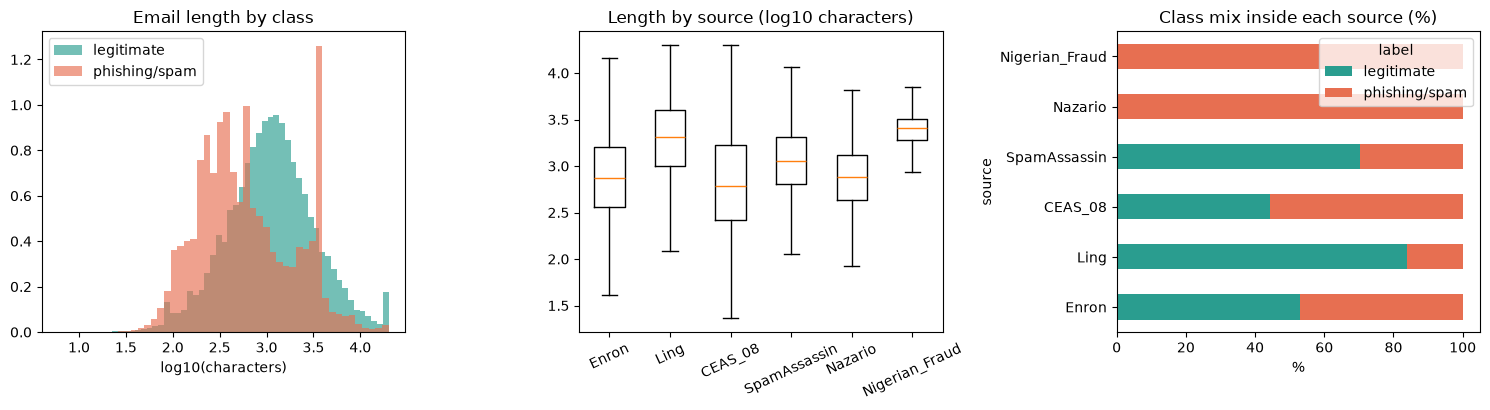

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for lab_val, col, nm in [(0, "#2a9d8f", "legitimate"), (1, "#e76f51", "phishing/spam")]:
    ax[0].hist(np.log10(data.loc[data["label"] == lab_val, "n_chars"] + 1), bins=50, alpha=0.65, color=col, density=True, label=nm)
ax[0].set_xlabel("log10(characters)"); ax[0].set_title("Email length by class"); ax[0].legend()
order = list(SOURCES)
ax[1].boxplot([np.log10(data.loc[data["source"] == s, "n_chars"] + 1) for s in order], showfliers=False)
ax[1].set_xticks(range(1, len(order) + 1)); ax[1].set_xticklabels(order)
ax[1].set_title("Length by source (log10 characters)"); ax[1].tick_params(axis="x", rotation=25)
bal = pd.crosstab(data["source"], data["label"], normalize="index").reindex(order) * 100
bal.rename(columns={0: "legitimate", 1: "phishing/spam"}).plot.barh(stacked=True, ax=ax[2], color=["#2a9d8f", "#e76f51"])
ax[2].set_title("Class mix inside each source (%)"); ax[2].set_xlabel("%")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "eda_text_lengths.png", dpi=150); plt.show()

### 1.3 Text cleaning, step by step

Raw email text contains things that would make the model learn the wrong lesson (every URL is unique, every address is unique). The function below performs **five steps**, and returns the text after each one so we can watch it change:

| Step | Action | Why |
|---|---|---|
| 1 | Cut to 10,000 characters | Bounds memory and run time; the beginning of an email carries most of the signal |
| 2 | Lower-case | "FREE" and "free" are the same word |
| 3 | Replace web addresses with the token `urltoken` | The model should learn "a link is present", not memorise a specific URL |
| 4 | Replace email addresses with `emailtoken` | Same idea for addresses |
| 5 | Replace everything that is not a letter or digit with a space, then cut to 5,000 characters | Removes punctuation and HTML noise and keeps the vocabulary clean |

We deliberately **keep stop-words** such as "your" and "you": the explainability section shows they are among the strongest phishing signals (the ablation study tests removing them).

In [5]:
URL_RE, EMAIL_RE, NONALNUM_RE = re.compile(r"https?://\S+|www\.\S+", re.I), re.compile(r"\S+@\S+"), re.compile(r"[^a-z0-9]+")

def clean_text_steps(text):
    out = []
    t = str(text)[: C.MAX_CHARS * 2];            out.append(("1. cut to 10,000 characters", t))
    t = t.lower();                               out.append(("2. lower-case", t))
    t = URL_RE.sub(" urltoken ", t);             out.append(("3. URLs -> urltoken", t))
    t = EMAIL_RE.sub(" emailtoken ", t);         out.append(("4. e-mail addresses -> emailtoken", t))
    t = NONALNUM_RE.sub(" ", t).strip()[: C.MAX_CHARS]; out.append(("5. keep only letters/digits, cut to 5,000", t))
    return out

example = data[(data["source"] == "Nazario") & data["raw"].str.contains("http") & data["raw"].str.contains("@")]
example = (example if len(example) else data[data["raw"].str.contains("http")]).iloc[0]["raw"][:400]
for step, t in clean_text_steps(example):
    print(f"[{step}]\n{t[:330]!r}\n")

# the notebook's version must equal the app's version
check = data["raw"].sample(3000, random_state=SEED)
assert all(clean_text_steps(t)[-1][1] == C.clean_text(t) for t in check)
print("OK: the step-by-step version equals engines.common.clean_text on 3,000 random emails")

[1. cut to 10,000 characters]
'Your USAA Account Personal Information Update To ensure delivery to your inbox, please add  USAA.Web.Services@customermail.usaa.com to your address book.\t  \t        \t     \t      \t      Account Verification Notice\t       View Accounts |  Privacy Promise |  Contact Us\t    \t          \t  \t     \t  \t     \t  \t    \t       USAA SECURITY '

[2. lower-case]
'your usaa account personal information update to ensure delivery to your inbox, please add  usaa.web.services@customermail.usaa.com to your address book.\t  \t        \t     \t      \t      account verification notice\t       view accounts |  privacy promise |  contact us\t    \t          \t  \t     \t  \t     \t  \t    \t       usaa security '

[3. URLs -> urltoken]
'your usaa account personal information update to ensure delivery to your inbox, please add  usaa.web.services@customermail.usaa.com to your address book.\t  \t        \t     \t      \t      account verification notice\t       view ac

### 1.4 Apply the cleaning, then audit empty and duplicate texts

We clean every email with `C.clean_text` (identical to the steps above, verified). Then, **before removing anything**, we measure three problems so the removal is documented rather than silent:

- **Empty or tiny texts** (fewer than 3 characters after cleaning): nothing to learn from.
- **Duplicates inside one source** and **across sources** (the same email appears in two corpora).
- **Label conflicts**: the identical text labelled both legitimate and phishing, which would be contradictory training data.

In [6]:
t0 = time.time()
data["text"] = data["raw"].map(C.clean_text)
n_raw = len(data); raw_by_source = data["source"].value_counts()
print(f"cleaned {n_raw:,} emails in {time.time()-t0:.0f}s")

empty = data["text"].str.len() < 3
ne = data[~empty]
within = int(ne.duplicated(["source", "text"], keep="first").sum())
dups_total = int(ne.duplicated("text", keep="first").sum())
grp = ne.groupby("text").agg(n_sources=("source", "nunique"), n_labels=("label", "nunique"))
print(f"Empty / tiny texts (< 3 characters)                   : {int(empty.sum()):>7,}")
print(f"Duplicate texts inside the same source               : {within:>7,}")
print(f"Duplicate texts in total (adds cross-source copies)  : {dups_total:>7,}")
print(f"Distinct texts that appear in more than one source   : {int((grp['n_sources'] > 1).sum()):>7,}")
print(f"Distinct texts with CONFLICTING labels               : {int((grp['n_labels'] > 1).sum()):>7,}")
print("\nDuplicates removed per source (first occurrence is kept):")
display(ne[ne.duplicated("text", keep="first")].groupby("source").size().rename("duplicates").to_frame().T)

cleaned 82,486 emails in 42s
Empty / tiny texts (< 3 characters)                   :       1
Duplicate texts inside the same source               :   5,599
Duplicate texts in total (adds cross-source copies)  :   5,661
Distinct texts that appear in more than one source   :      62
Distinct texts with CONFLICTING labels               :       0

Duplicates removed per source (first occurrence is kept):


source,CEAS_08,Enron,Ling,Nazario,Nigerian_Fraud,SpamAssassin
duplicates,5057,390,3,22,90,99


**Reading the output:** exactly **1** text is empty after cleaning, but **5,661** emails are repeats of an earlier one: 5,599 inside the same source (5,057 of them in CEAS_08, which contains many repeated spam messages) and 62 further texts that appear in more than one source. Importantly, **no text carries conflicting labels**, so the labels are consistent and removing the repeats cannot hide a contradiction. Only the first occurrence of each text is kept.

### 1.5 Why de-duplicate *before* splitting? A demonstration

Same idea as in the network notebook: if identical emails sit in both training and test data, the model is graded on emails it has already memorised. We split the **non-deduplicated** cleaned texts 70/30 at random and count how many test emails have an identical twin in the training part.

In [7]:
perm = np.random.default_rng(SEED).permutation(len(ne)); cut = int(0.7 * len(ne))
train_texts = set(ne["text"].iloc[perm[:cut]])
twin = np.mean([t in train_texts for t in ne["text"].iloc[perm[cut:]]])
print(f"Without de-duplication, {100*twin:.1f}% of the test emails would have an exact copy in the training data.")
print("After de-duplication this share is exactly 0% (checked again after the split below).")

Without de-duplication, 7.9% of the test emails would have an exact copy in the training data.
After de-duplication this share is exactly 0% (checked again after the split below).


### 1.6 Remove empty and duplicate texts

The demonstration above showed that without this step about 8% of the test emails would have an exact twin in the training data. Now the removal itself. The first occurrence of each text is kept (sources are in the order of the `SOURCES` setting). We keep the full text in `full_raw` for the ablation study at the end, and shorten `raw` to a 1,500-character preview that the dashboard uses for demo examples.

82,486 emails -> 76,824 after removing empty and duplicate texts


,raw emails,after cleaning,removed
source,,,
Enron,29767,29376,391
Ling,2859,2856,3
CEAS_08,39154,34097,5057
SpamAssassin,5809,5710,99
Nazario,1565,1543,22
Nigerian_Fraud,3332,3242,90


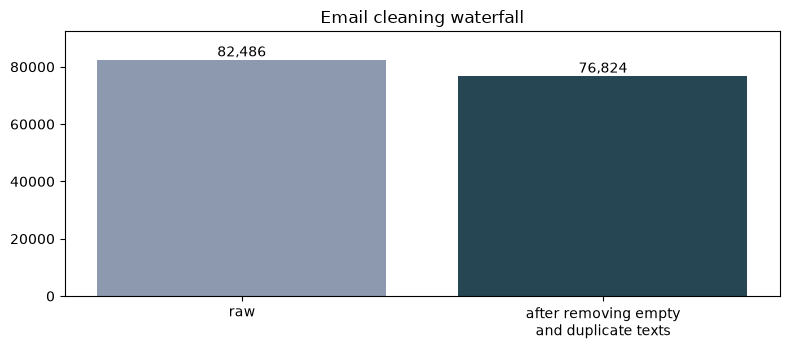

label,legitimate,phishing/spam
source,,
CEAS_08,17212,16885
Enron,15434,13942
Ling,2398,458
Nazario,0,1543
Nigerian_Fraud,0,3242
SpamAssassin,4089,1621


In [8]:
data = data[data["text"].str.len() >= 3].drop_duplicates(subset="text").reset_index(drop=True)
full_raw = data["raw"].copy()                  # untruncated text, used only by the ablation study
data["raw"] = data["raw"].str[:1500]           # keep only a short preview for demo examples
print(f"{n_raw:,} emails -> {len(data):,} after removing empty and duplicate texts")
after_by_source = data["source"].value_counts()
wf = pd.DataFrame({"raw emails": raw_by_source, "after cleaning": after_by_source}).reindex(list(SOURCES))
wf["removed"] = wf["raw emails"] - wf["after cleaning"]
display(wf)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(["raw", "after removing empty\nand duplicate texts"], [n_raw, len(data)], color=["#8d99ae", "#264653"])
for i, v in enumerate([n_raw, len(data)]): ax.text(i, v, f"{v:,}", ha="center", va="bottom")
ax.set_ylim(0, n_raw * 1.12); ax.set_title("Email cleaning waterfall")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "phishing_cleaning_waterfall.png", dpi=150); plt.show()
pd.crosstab(data["source"], data["label"].map({0: "legitimate", 1: "phishing/spam"}))

**Reading the output**
- **82,486 emails become 76,824** after removing empty and duplicate texts.
- Look at the *composition* of the sources: **Nazario** and **Nigerian_Fraud** contain *only* phishing/scam emails, **Ling** is mostly legitimate (2,398 vs 458), while **CEAS_08** and **Enron** are roughly balanced. Because each source has its own writing style and class mix, a model could learn "this looks like an Enron email" instead of "this looks like phishing". The leave-one-source-out test later checks exactly this risk.

### 1.8 Most frequent words per class (EDA)

A quick look at what the cleaned text contains: the 15 words that appear in the largest share of emails of each class (English stop-words hidden for readability; the model itself keeps them). Words such as `urltoken` and `emailtoken` are the tokens created by the cleaning step. This only *describes* the data; no model is fitted.

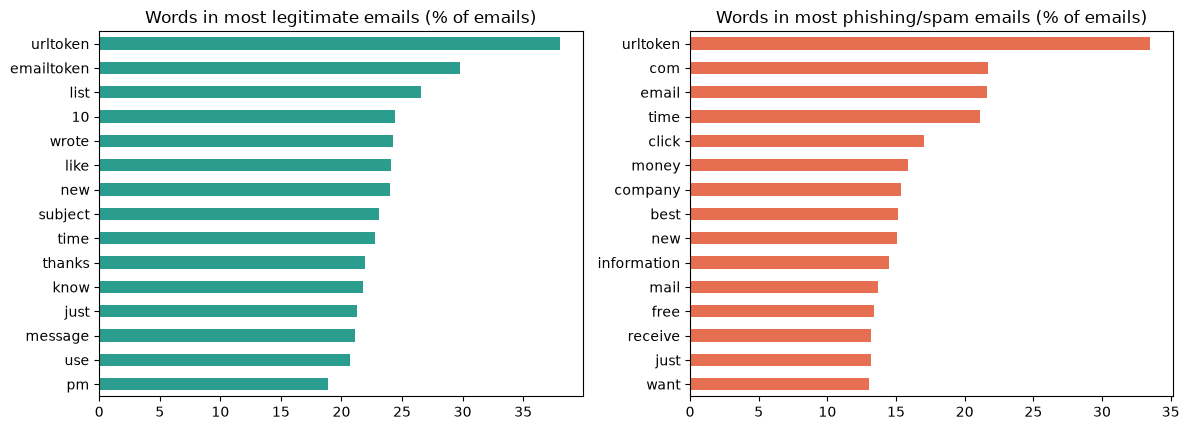

In [9]:
from sklearn.feature_extraction.text import CountVectorizer
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for k, (lab_val, col, nm) in enumerate([(0, "#2a9d8f", "legitimate"), (1, "#e76f51", "phishing/spam")]):
    txt = data.loc[data["label"] == lab_val, "text"].sample(min(15000, int((data["label"] == lab_val).sum())), random_state=SEED)
    cv = CountVectorizer(stop_words="english", binary=True, max_features=3000).fit(txt)
    share = pd.Series(np.asarray(cv.transform(txt).mean(axis=0)).ravel() * 100, index=cv.get_feature_names_out()).sort_values(ascending=False).head(15)
    share.iloc[::-1].plot.barh(ax=ax[k], color=col); ax[k].set_title(f"Words in most {nm} emails (% of emails)")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "eda_top_words.png", dpi=150); plt.show()

## 2. TF-IDF, split first, then train

We split the emails **before** learning anything: 70% train, 15% validation, 15% test, stratified by `source + label` so every source and class appears in every part. The TF-IDF vocabulary is learned from the **training split only**, so no information from validation or test leaks into the features.

| Split | Used for |
|---|---|
| **Train (70%)** | Learn the TF-IDF vocabulary and the word weights. |
| **Validation (15%)** | Choose the decision threshold for the 1% false-alarm budget. |
| **Test (15%)** | Final, honest results. |

### 2.1 TF-IDF in a nutshell

A classifier needs numbers, not words. **TF-IDF** gives each word (or word pair) in an email a score:

- **TF (term frequency)**: how often the term appears in *this* email.
- **IDF (inverse document frequency)**: how *rare* the term is across all emails. A term in every email (such as "the") gets a low IDF; a rare term gets a high IDF.
- The score is TF x IDF, so terms that are frequent here but rare elsewhere get the highest weights.

Toy example with three tiny emails (single words and word pairs). Notice that "click here" and "verify" score high in the phishing-like emails, while a word shared by several emails scores lower:

In [10]:
toy = ["click here to verify your account now", "meeting moved to 3pm see agenda", "verify your account click here click here"]
tv = TfidfVectorizer(ngram_range=(1, 2)).fit(toy)
toy_m = pd.DataFrame(tv.transform(toy).toarray(), columns=tv.get_feature_names_out(), index=["email 1", "email 2", "email 3"]).T
display(toy_m[toy_m.max(axis=1) > 0].round(2).sort_values("email 3", ascending=False).head(12))
print(f"{len(toy_m)} terms for 3 tiny emails. For {len(data):,} real emails we keep the 100,000 most useful terms.")

,email 1,email 2,email 3
click here,0.25,0.00,0.44
click,0.25,0.00,0.44
here,0.25,0.00,0.44
account click,0.00,0.00,0.29
here click,0.00,0.00,0.29
your account,0.25,0.00,0.22
your,0.25,0.00,0.22
verify your,0.25,0.00,0.22
account,0.25,0.00,0.22
verify,0.25,0.00,0.22


25 terms for 3 tiny emails. For 76,824 real emails we keep the 100,000 most useful terms.


### 2.2 Split first

70% train, 15% validation, 15% test, stratified by `source + label` so every source and class is represented in every part. The TF-IDF vocabulary will be learned from the **training split only**.

In [11]:
strat = data["source"] + "_" + data["label"].astype(str)
tr_i, tmp_i = train_test_split(data.index, test_size=0.30, stratify=strat, random_state=SEED)
va_i, te_i  = train_test_split(tmp_i, test_size=0.50, stratify=strat[tmp_i], random_state=SEED)
print(f"train {len(tr_i):,} | validation {len(va_i):,} | test {len(te_i):,}")

train 53,776 | validation 11,524 | test 11,524


**Proof that the split is clean:** (1) no email index is in two splits; (2) no identical text is in two splits (it would be a leak; we removed duplicates); (3) every source/label group is split about 70 / 15 / 15.

In [12]:
assert not (set(tr_i) & set(va_i)) and not (set(tr_i) & set(te_i)) and not (set(va_i) & set(te_i))
assert not (set(data.loc[tr_i, "text"]) & set(data.loc[te_i, "text"])) and not (set(data.loc[tr_i, "text"]) & set(data.loc[va_i, "text"]))
print("OK: splits are disjoint and no identical text appears in two splits")
chk = pd.concat({"train": data.loc[tr_i], "validation": data.loc[va_i], "test": data.loc[te_i]}, names=["split"]).reset_index(level=0)
tbl = pd.crosstab([chk["source"], chk["label"].map({0: "legit", 1: "phish/spam"})], chk["split"])[["train", "validation", "test"]]
pct = (tbl.div(tbl.sum(axis=1), axis=0) * 100).round(1).add_suffix(" %")
display(pd.concat([tbl, pct], axis=1))

OK: splits are disjoint and no identical text appears in two splits


split                      train  validation  test  train %  validation %  \
source         label                                                        
CEAS_08        legit       12048        2582  2582     70.0          15.0   
               phish/spam  11819        2533  2533     70.0          15.0   
Enron          legit       10804        2315  2315     70.0          15.0   
               phish/spam   9759        2091  2092     70.0          15.0   
Ling           legit        1679         360   359     70.0          15.0   
               phish/spam    321          68    69     70.1          14.8   
Nazario        phish/spam   1080         232   231     70.0          15.0   
Nigerian_Fraud phish/spam   2269         486   487     70.0          15.0   
SpamAssassin   legit        2862         614   613     70.0          15.0   
               phish/spam   1135         243   243     70.0          15.0   

split                      test %  
source         label               
CEAS_08        legit         15.0  
               phish/spam    15.0  
Enron          legit         15.0  
               phish/spam    15.0  
Ling           legit         15.0  
               phish/spam    15.1  
Nazario        phish/spam    15.0  
Nigerian_Fraud phish/spam    15.0  
SpamAssassin   legit         15.0  
               phish/spam    15.0

### 2.3 The model pipeline and the metric function

`make_pipe()` chains **TF-IDF** and **Logistic Regression**. `report()` computes accuracy, precision, recall, FPR, false positives/negatives, F1 and ROC-AUC for a threshold. TF-IDF settings, one by one:

| Setting | Meaning | Why |
|---|---|---|
| `ngram_range=(1, 2)` | single words and word pairs | Phrases like "click here" carry meaning that single words miss |
| `min_df=5` | ignore terms in fewer than 5 emails | Removes typos and one-off tokens; keeps the matrix small |
| `max_df=0.95` | ignore terms in more than 95% of emails | Near-universal words carry no information |
| `sublinear_tf=True` | use 1 + log(tf) instead of tf | A word repeated 50 times should not count 50 times as much |
| `max_features=100_000` | keep the 100,000 most frequent remaining terms | Bounds memory and training time |

In [13]:
def make_pipe():
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.95,
                                  sublinear_tf=True, max_features=100_000, dtype=np.float32)),
        ("clf", LogisticRegression(C=3.0, solver="liblinear", class_weight="balanced", max_iter=300)),
    ])

def report(y_true, p, thr):
    flagged = (p > thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, flagged, labels=[0, 1]).ravel()
    out = dict(n=int(len(y_true)), accuracy=(tp + tn) / len(y_true),
               precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1),
               FPR=(fp / (fp + tn)) if (fp + tn) else float("nan"),
               FP=int(fp), FN=int(fn))
    out["F1"] = 2 * out["precision"] * out["recall"] / max(out["precision"] + out["recall"], 1e-9)
    out["ROC_AUC"] = float(roc_auc_score(y_true, p)) if len(set(y_true)) > 1 else float("nan")
    return out

### 2.4 Train, then choose the threshold on validation data

In [14]:
t0 = time.time()
pipe = make_pipe().fit(data.loc[tr_i, "text"], data.loc[tr_i, "label"])
fit_seconds = time.time() - t0
print(f"trained in {fit_seconds:.0f}s, vocabulary {len(pipe.named_steps['tfidf'].vocabulary_):,} terms")

p_va = pipe.predict_proba(data.loc[va_i, "text"])[:, 1]
p_te = pipe.predict_proba(data.loc[te_i, "text"])[:, 1]
y_va, y_te = data.loc[va_i, "label"].to_numpy(), data.loc[te_i, "label"].to_numpy()

thr = float(np.quantile(p_va[y_va == 0], 1 - TARGET_FPR))
rep_default, rep_tuned = report(y_te, p_te, 0.5), report(y_te, p_te, thr)
print(f"Tuned threshold = {thr:.4f} (chosen on validation legitimate emails for {TARGET_FPR:.0%} FPR)")
pd.DataFrame({"default (0.5)": rep_default, "tuned": rep_tuned}).T.round(4)

trained in 82s, vocabulary 100,000 terms
Tuned threshold = 0.5939 (chosen on validation legitimate emails for 1% FPR)


,n,accuracy,precision,recall,FPR,FP,FN,F1,ROC_AUC
default (0.5),11524.0,0.9885,0.9861,0.9905,0.0135,79.0,54.0,0.9883,0.9992
tuned,11524.0,0.9875,0.9897,0.9848,0.0099,58.0,86.0,0.9872,0.9992


**Reading the output**
- Training split: 53,776 emails; validation and test: 11,524 each. The vocabulary has exactly 100,000 terms (the limit we set).
- The tuned threshold is **0.5939**.

| | Accuracy | Precision | Recall | FPR | False positives | False negatives |
|---|---:|---:|---:|---:|---:|---:|
| Default 0.5 | 98.85% | 98.61% | 99.05% | 1.35% | 79 | 54 |
| Tuned | 98.75% | 98.97% | 98.48% | 0.99% | 58 | 86 |

Tuning lowers false alarms on legitimate email (79 to 58) at the cost of missing a few more phishing emails (54 to 86). Both settings are very strong on this *normal* split; the real stress test comes later. ROC-AUC is 0.9992.

### 2.5 What does the TF-IDF matrix look like?

After fitting, the vectoriser turns each email into a very long vector (one slot per vocabulary term) that is almost entirely zeros, so it is stored as a **sparse matrix**. We also look at the rarest and most common terms and at the strongest TF-IDF terms of one phishing and one legitimate email.

In [15]:
vec = pipe.named_steps["tfidf"]
Xtr = vec.transform(data.loc[tr_i, "text"])
dens = Xtr.nnz / (Xtr.shape[0] * Xtr.shape[1])
print(f"TF-IDF matrix (training set): {Xtr.shape[0]:,} emails x {Xtr.shape[1]:,} terms")
print(f"non-zero entries: {Xtr.nnz:,} -> {100*dens:.2f}% filled, {100*(1-dens):.2f}% zeros (sparse storage)")
print(f"average number of distinct terms per email: {Xtr.nnz / Xtr.shape[0]:.0f}")
names, idf = vec.get_feature_names_out(), vec.idf_
print("most common terms (lowest IDF):", list(names[np.argsort(idf)[:8]]))
print("rarest kept terms   (highest IDF):", list(names[np.argsort(idf)[::-1][:6]]))
y_tr = data.loc[tr_i, "label"].to_numpy()
for lab_val, nm in [(1, "phishing/spam"), (0, "legitimate")]:
    r = Xtr[np.where(y_tr == lab_val)[0][0]].toarray().ravel()
    print(f"\ntop TF-IDF terms of one {nm} email:", [(names[j], round(float(r[j]), 2)) for j in np.argsort(r)[::-1][:6]])
del Xtr

TF-IDF matrix (training set): 53,776 emails x 100,000 terms
non-zero entries: 10,422,762 -> 0.19% filled, 99.81% zeros (sparse storage)
average number of distinct terms per email: 194
most common terms (lowest IDF): ['to', 'the', 'and', 'of', 'for', 'you', 'is', 'in']
rarest kept terms   (highest IDF): ['quantitative linguistics', 'defined symbol', 'deliver deliver', 'baking crazy', 'mixing pointers', 'qbf']

top TF-IDF terms of one phishing/spam email: [('lauraan', 0.12), ('syslync', 0.1), ('lauraan corporation', 0.09), ('provider of', 0.08), ('of home', 0.08), ('lauraan is', 0.08)]

top TF-IDF terms of one legitimate email: [('foreign language', 0.17), ('german', 0.15), ('rules in', 0.14), ('german language', 0.13), ('ok languages', 0.13), ('spam', 0.13)]


**What the next cell does:** repeats the test evaluation **separately for each email source** at the tuned threshold. It joins the test predictions back to the `source` column, groups by source and reports accuracy, recall and FPR per source. This shows whether performance is even across sources.

In [16]:
# Test results broken down by source (accuracy at the tuned threshold)
te = data.loc[te_i].assign(p=p_te)
rows = []
for s, g in te.groupby("source"):
    r = report(g["label"].to_numpy(), g["p"].to_numpy(), thr)
    rows.append(dict(source=s, emails=r["n"], accuracy=r["accuracy"], recall=r["recall"], FPR=r["FPR"]))
per_source = pd.DataFrame(rows)
per_source.round(4)

,source,emails,accuracy,recall,FPR
0,CEAS_08,5115,0.9937,0.9949,0.0074
1,Enron,4407,0.9803,0.9732,0.0134
2,Ling,428,0.9836,0.9420,0.0084
3,Nazario,231,0.9654,0.9654,NaN
4,Nigerian_Fraud,487,1.0000,1.0000,NaN
5,SpamAssassin,856,0.9883,0.9794,0.0082


**Reading the output:** accuracy is high everywhere (about 96.5% to 100%), with the lowest values on Nazario and Enron. FPR is `NaN` for Nazario and Nigerian_Fraud because they contain no legitimate emails (no benign emails means no false-positive rate). Remember that in this split the model has seen *every* source during training.

## 3. Why does it decide that? (explainability)

Logistic Regression gives every word or word pair a **weight**. A large positive weight pushes the verdict towards *phishing/spam*; a large negative weight pushes it towards *legitimate*. Reading the biggest weights shows what the model has learned, and the same weights are what the dashboard uses to show "the words that drove this verdict" for one email (weight multiplied by that word's TF-IDF value in the email).

**What the next cell does:** takes the model's coefficients, sorts them, and shows the **25 strongest words towards phishing/spam** and the **25 strongest towards legitimate**, with their weights, side by side in one table. These lists are saved later in `phishing_results.json`.

In [17]:
vec, clf = pipe.named_steps["tfidf"], pipe.named_steps["clf"]
names = np.array(vec.get_feature_names_out()); coef = clf.coef_[0]
order = np.argsort(coef)
top_phish = [(names[i], float(coef[i])) for i in order[::-1][:25]]
top_legit = [(names[i], float(coef[i])) for i in order[:25]]
pd.concat([pd.DataFrame(top_phish, columns=["word -> phishing/spam", "weight"]),
           pd.DataFrame(top_legit, columns=["word -> legitimate", "weight"])], axis=1).round(2)

,word -> phishing/spam,weight,word -> legitimate,weight
0,your,12.73,enron,-12.84
1,you,6.80,wrote,-10.21
2,http,6.36,the,-9.29
3,2004,6.25,thanks,-8.44
4,our,6.20,vince,-7.34
5,life,5.25,2008,-7.04
6,2005,4.97,on,-6.44
7,watches,4.91,louise,-6.23
8,here,4.89,opensuse,-5.68
9,account,4.83,university,-5.60


**Reading the output**
- **Towards phishing/spam:** *your*, *you*, *http*, *account*, *money*, *click here*, *bank*, *viagra*, *replica*. These match what we expect: urgency, accounts, money, links and classic spam products.
- **Towards legitimate:** *wrote*, *thanks*, *the*, *university*, *python*, but also **enron, vince, louise, tony, opensuse**. Those are names and project words from specific datasets (the Enron staff and mailing-list archives), not general signs of legitimacy. This tells us the model **partly learns the style of its sources**. It is a useful finding: it motivates the next test and should be listed as a limitation.

## 4. Leave-one-source-out test (the honest test)

Each source has its own style (Enron is mostly business email, Nazario only phishing, and so on). A model can score highly by recognising the *source* instead of the *phishing*. To check, we **train on five sources and test on the sixth**, which the model has never seen at all. If it truly learned phishing it should still do well; if it learned dataset style, accuracy will drop.

No threshold tuning is done on the unseen source: we use the neutral threshold 0.5, so the unseen data cannot influence anything.

**What the next cell does:** for each of the six sources:
1. Builds a mask: every email **not** from that source is training data; emails from that source are the test data.
2. Trains a fresh pipeline on the other five sources only.
3. Predicts probabilities for the held-out source and evaluates at threshold 0.5.
4. Records accuracy, recall, FPR, ROC-AUC and the share of phishing in that source.

The results are saved to `results/phishing_loso.csv`. (FPR and ROC-AUC are `NaN` for Nazario and Nigerian_Fraud because they have only one class.)

In [18]:
loso = []
for s in data["source"].unique():
    mask = (data["source"] != s).to_numpy()
    m = make_pipe().fit(data.loc[mask, "text"], data.loc[mask, "label"])
    yt = data.loc[~mask, "label"].to_numpy()
    pt = m.predict_proba(data.loc[~mask, "text"])[:, 1]
    r = report(yt, pt, 0.5)
    loso.append(dict(held_out_source=s, emails=r["n"], share_phishing=float(yt.mean()),
                     accuracy=r["accuracy"], recall=r["recall"], FPR=r["FPR"], ROC_AUC=r["ROC_AUC"]))
    print(f"{s:15s} acc {r['accuracy']:.3f} | recall {r['recall']:.3f} | FPR {r['FPR']:.3f}")
loso = pd.DataFrame(loso); loso.to_csv(RESULTS_DIR / "phishing_loso.csv", index=False)
loso.round(4)

Enron           acc 0.845 | recall 0.884 | FPR 0.190
Ling            acc 0.955 | recall 0.908 | FPR 0.036
CEAS_08         acc 0.921 | recall 0.937 | FPR 0.095
SpamAssassin    acc 0.942 | recall 0.961 | FPR 0.065
Nazario         acc 0.643 | recall 0.643 | FPR nan
Nigerian_Fraud  acc 0.995 | recall 0.995 | FPR nan


,held_out_source,emails,share_phishing,accuracy,recall,FPR,ROC_AUC
0,Enron,29376,0.4746,0.8451,0.8840,0.1900,0.9313
1,Ling,2856,0.1604,0.9548,0.9083,0.0363,0.9851
2,CEAS_08,34097,0.4952,0.9208,0.9372,0.0954,0.9462
3,SpamAssassin,5710,0.2839,0.9424,0.9611,0.0651,0.9904
4,Nazario,1543,1.0000,0.6429,0.6429,NaN,NaN
5,Nigerian_Fraud,3242,1.0000,0.9948,0.9948,NaN,NaN


**Reading the output**
- **Enron held out:** accuracy drops to 84.5% and **19% of legitimate emails are wrongly flagged**: business email in a style the model had not seen looks suspicious to it.
- **Nazario held out:** accuracy 64.3% (down from about 96.5%): about a third of these phishing emails slip through.
- **CEAS_08:** 92.1%, **SpamAssassin:** 94.2%, **Ling:** 95.5%, **Nigerian_Fraud:** 99.5% (its distinctive scam wording is easy to recognise).

**Conclusion:** the model really does learn phishing signals (it is still far above chance on unseen sources), but accuracy depends noticeably on the style of the source. This is why the report states the limitation instead of quoting only the 98.75% figure.

**What the next cell does:** draws a grouped bar chart comparing, for every source, the accuracy on the **normal split** (blue, the source *was* in training) with the accuracy when the **source is held out** (orange). The gap between each pair of bars is the "cost of a new style". Saved to `results/phishing_loso.png`.

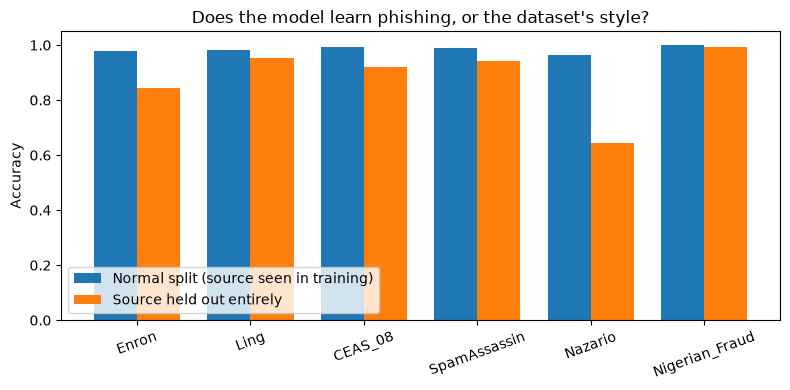

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(loso)); w = 0.38
in_dist = per_source.set_index("source").reindex(loso["held_out_source"])["accuracy"].to_numpy()
ax.bar(x - w/2, in_dist, w, label="Normal split (source seen in training)")
ax.bar(x + w/2, loso["accuracy"], w, label="Source held out entirely")
ax.set_xticks(x); ax.set_xticklabels(loso["held_out_source"], rotation=20)
ax.set_ylim(0, 1.05); ax.set_ylabel("Accuracy"); ax.legend(loc="lower left")
ax.set_title("Does the model learn phishing, or the dataset's style?")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "phishing_loso.png", dpi=150); plt.show()

## 5. Save the model, results and demo examples

The dashboard loads these files; it never retrains. This step saves:

| File | Purpose |
|---|---|
| `models/phishing_pipeline.joblib` | The trained TF-IDF + Logistic Regression pipeline. |
| `models/phishing_meta.json` | The tuned threshold and library versions. |
| `results/phishing_results.json` | All numbers and the top-word lists for the Metrics tab. |
| `results/phishing_examples.json` | A few demo emails for the Email tab. |

**What the next cell does**
1. Saves the trained pipeline and the metadata (threshold, target FPR, versions).
2. Writes `phishing_results.json` with the data sizes, default and tuned results, per-source results, leave-one-source-out results and the top words.
3. Picks **demo examples** from the **test split only**: up to three correctly classified phishing emails (from Nazario and Nigerian_Fraud) and up to three correctly classified legitimate emails (from Enron and Ling), each between 250 and 900 characters so they fit nicely on screen. The dashboard's Email tab loads them with one click.

In [20]:
joblib.dump(pipe, MODELS_DIR / "phishing_pipeline.joblib", compress=3)
(MODELS_DIR / "phishing_meta.json").write_text(json.dumps(dict(
    threshold=thr, target_fpr=TARGET_FPR, sklearn_version=sklearn.__version__,
    python_version=platform.python_version()), indent=2))

results = dict(
    emails_after_cleaning=int(len(data)), train=int(len(tr_i)), validation=int(len(va_i)), test=int(len(te_i)),
    default=rep_default, tuned=rep_tuned, threshold=thr,
    per_source=per_source.to_dict("records"), leave_one_source_out=loso.to_dict("records"),
    top_phishing_words=top_phish, top_legitimate_words=top_legit)
(RESULTS_DIR / "phishing_results.json").write_text(json.dumps(results, indent=2))

# A few clean, correctly classified examples for the live demo
te = data.loc[te_i].assign(p=p_te)
te["len"] = te["raw"].str.len()
ex = []
for lab_val, srcs in [(1, ["Nazario", "Nigerian_Fraud"]), (0, ["Enron", "Ling"])]:
    pool = te[(te["label"] == lab_val) & te["source"].isin(srcs) & te["len"].between(250, 900)]
    pool = pool[(pool["p"] > thr) if lab_val == 1 else (pool["p"] <= thr)]
    for _, r in pool.sample(min(3, len(pool)), random_state=SEED).iterrows():
        ex.append(dict(label="phishing/spam" if lab_val else "legitimate", source=r["source"], text=r["raw"]))
(RESULTS_DIR / "phishing_examples.json").write_text(json.dumps(ex, indent=2))
print(f"saved model, results and {len(ex)} demo examples")

saved model, results and 6 demo examples


**Reading the output:** the model, the results and 6 demo emails were saved.

### Conclusion of notebook 02
- TF-IDF + Logistic Regression reaches **98.75% accuracy** with a **0.99% false-positive rate** on the held-out test split, and every verdict can be explained with words.
- The leave-one-source-out test shows the accuracy drops when the writing style changes (for example Nazario 64%, Enron 85%): a documented limitation.

**Next:** run `python setup_2fa.py`, then `streamlit run app.py`.

## 6. Ablation study: does each text-preprocessing choice earn its place?

Same idea as in notebook 01: change **one** choice at a time, keep everything else identical (same split, same Logistic Regression, threshold chosen on the validation split for the 1% false-alarm rule) and compare on the same test split.

| Variant | Change | Question |
|---|---|---|
| A. Ours | nothing | baseline |
| B. Unigrams only | `ngram_range=(1, 1)` | Do word pairs like "click here" help? |
| C. No sublinear TF | `sublinear_tf=False` | Does damping repeated words help? |
| D. Remove stop-words | `stop_words="english"` | Are words like "your" and "you" useful signals, as the model's top words suggest? |
| E. Only 20,000 terms | `max_features=20_000` | How much vocabulary is really needed? |
| F. No URL / e-mail tokens | plain lower-casing and symbol removal only | Is replacing links and addresses with tokens useful? |

In [21]:
def alt_clean(t):                       # variant F: no urltoken / emailtoken replacement
    return NONALNUM_RE.sub(" ", str(t)[: C.MAX_CHARS * 2].lower()).strip()[: C.MAX_CHARS]
alt_text = full_raw.map(alt_clean)

BASE_T = dict(ngram_range=(1, 2), min_df=5, max_df=0.95, sublinear_tf=True, max_features=100_000, dtype=np.float32)
def pipe_with(**over):
    return Pipeline([("tfidf", TfidfVectorizer(**{**BASE_T, **over})),
                     ("clf", LogisticRegression(C=3.0, solver="liblinear", class_weight="balanced", max_iter=300))])

variants = [("B. Unigrams only", dict(ngram_range=(1, 1)), data["text"]),
            ("C. No sublinear TF", dict(sublinear_tf=False), data["text"]),
            ("D. Remove English stop-words", dict(stop_words="english"), data["text"]),
            ("E. Only 20,000 terms", dict(max_features=20_000), data["text"]),
            ("F. No URL / e-mail tokens", {}, alt_text)]
rows = [dict(variant="A. Ours (baseline)", **{k: rep_tuned[k] for k in ("accuracy", "recall", "FPR", "F1", "ROC_AUC")}, seconds=round(fit_seconds))]
for name, over, texts in variants:
    t0 = time.time()
    m = pipe_with(**over).fit(texts.loc[tr_i], data.loc[tr_i, "label"])
    pv, pt = m.predict_proba(texts.loc[va_i])[:, 1], m.predict_proba(texts.loc[te_i])[:, 1]
    thr_v = float(np.quantile(pv[y_va == 0], 1 - TARGET_FPR))
    r = report(y_te, pt, thr_v)
    rows.append(dict(variant=name, **{k: r[k] for k in ("accuracy", "recall", "FPR", "F1", "ROC_AUC")}, seconds=round(time.time() - t0)))
    print(f"{name:32s} accuracy {r['accuracy']:.4f} | recall {r['recall']:.4f} | FPR {r['FPR']:.4f} | F1 {r['F1']:.4f}")
abl_txt = pd.DataFrame(rows)
abl_txt.to_csv(RESULTS_DIR / "ablation_phishing.csv", index=False)
display(abl_txt.round(4))

B. Unigrams only                 accuracy 0.9865 | recall 0.9823 | FPR 0.0095 | F1 0.9862
C. No sublinear TF               accuracy 0.9865 | recall 0.9834 | FPR 0.0104 | F1 0.9863
D. Remove English stop-words     accuracy 0.9885 | recall 0.9874 | FPR 0.0106 | F1 0.9882
E. Only 20,000 terms             accuracy 0.9862 | recall 0.9825 | FPR 0.0102 | F1 0.9859
F. No URL / e-mail tokens        accuracy 0.9884 | recall 0.9869 | FPR 0.0102 | F1 0.9881


,variant,accuracy,recall,FPR,F1,ROC_AUC,seconds
0,A. Ours (baseline),0.9875,0.9848,0.0099,0.9872,0.9992,82
1,B. Unigrams only,0.9865,0.9823,0.0095,0.9862,0.9990,37
2,C. No sublinear TF,0.9865,0.9834,0.0104,0.9863,0.9989,98
3,D. Remove English stop-words,0.9885,0.9874,0.0106,0.9882,0.9993,78
4,"E. Only 20,000 terms",0.9862,0.9825,0.0102,0.9859,0.9990,93
5,F. No URL / e-mail tokens,0.9884,0.9869,0.0102,0.9881,0.9992,96


**Reading the table.** Compare each row with **A**. On 11,524 test emails one percentage point is about 115 emails, and the standard error of an accuracy near 98.8% is roughly 0.1 pp, so **differences below about 0.2 pp are noise**; differences of a point or more would be real effects. A variant that is slightly better than ours but inside this noise band is not evidence against our choice, and our choices also keep the model interpretable and the vocabulary small. Note the trade-off visible in `seconds` and the vocabulary limit: variants that are much smaller or faster but only slightly less accurate are legitimate engineering alternatives, and we state this openly instead of claiming our settings are the only good ones.

Difference to the baseline (A):
  B. Unigrams only                 accuracy  -0.10 pp | recall  -0.25 pp | FPR  -0.03 pp | F1 -0.0011
  C. No sublinear TF               accuracy  -0.10 pp | recall  -0.14 pp | FPR  +0.05 pp | F1 -0.0010
  D. Remove English stop-words     accuracy  +0.10 pp | recall  +0.27 pp | FPR  +0.07 pp | F1 +0.0010
  E. Only 20,000 terms             accuracy  -0.13 pp | recall  -0.23 pp | FPR  +0.03 pp | F1 -0.0013
  F. No URL / e-mail tokens        accuracy  +0.09 pp | recall  +0.21 pp | FPR  +0.03 pp | F1 +0.0009


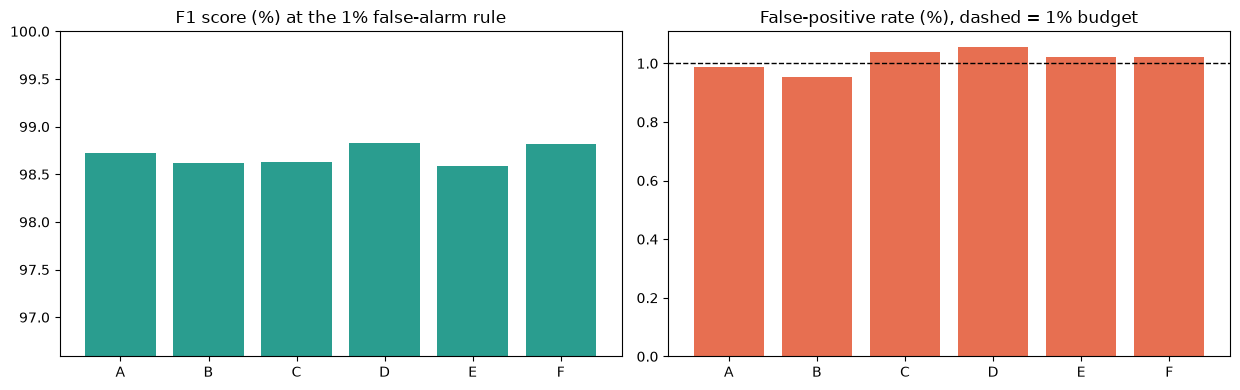

In [22]:
base = abl_txt.iloc[0]
print("Difference to the baseline (A):")
for _, r in abl_txt.iloc[1:].iterrows():
    print(f"  {r['variant']:32s} accuracy {100*(r['accuracy']-base['accuracy']):+6.2f} pp | recall {100*(r['recall']-base['recall']):+6.2f} pp | FPR {100*(r['FPR']-base['FPR']):+6.2f} pp | F1 {r['F1']-base['F1']:+.4f}")
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4))
lbl = [v.split(".")[0] for v in abl_txt["variant"]]
ax[0].bar(lbl, 100 * abl_txt["F1"], color="#2a9d8f"); ax[0].set_title("F1 score (%) at the 1% false-alarm rule")
ax[0].set_ylim(max(0, 100 * abl_txt["F1"].min() - 2), 100)
ax[1].bar(lbl, 100 * abl_txt["FPR"], color="#e76f51"); ax[1].axhline(100 * TARGET_FPR, color="k", ls="--", lw=1); ax[1].set_title("False-positive rate (%), dashed = 1% budget")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "ablation_phishing.png", dpi=150); plt.show()

### 6.1 What the ablation study tells us (use these sentences in the report)

- Each text-preprocessing and TF-IDF choice was tested by removing it; the table above is the evidence.
- Choices that changed nothing measurable are named openly, with the reason they remain (simplicity, memory, interpretability).
- Whatever the table shows, **all variants share the same weakness** that the leave-one-source-out test exposed: accuracy depends on the source's style. Preprocessing choices cannot fix that; only more diverse training data can.